# Comparação MDF × MVF — produtor central

Compara os dois métodos usando a mesma malha, permeabilidade heterogênea, parâmetros físicos, condição inicial, poço produtor e duração. Os gráficos mostram perfis horizontais e verticais que cruzam o poço no tempo final.

A velocidade mostrada é o módulo do vetor reconstruído nas células a partir das velocidades nas faces. O arquivo de permeabilidade existente é carregado de `data/permeabilidade.csv`; o notebook não gera outro campo. A última seção aumenta a malha quadrada até 29×29, simula 30 dias e compara dois conjuntos de parâmetros idênticos para MDF e MVF.


In [1]:
from pathlib import Path
import sys

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import matplotlib.pyplot as plt

from mdf.implicita_2d import implicita_2d as implicita_mdf
from mvf.implicita_2d import implicita_2d as implicita_mvf
from core.permeabilidade2d import carregar_permeabilidade
from core.velocidade2d import calcular_velocidade

plt.rcParams.update({"font.family": "sans-serif", "font.size": 10})


In [2]:
p0 = 20.684e6
pwf = 15.0e6
Lx = Ly = 1000.0
h = 30.0
rw = 0.10
phi = 0.22
ct = 3.046e-9
mu = 1.0e-3
t_d = 10
t_final = t_d * 86400
nx = ny = 21
nt = 500
iw = nx // 2
jw = ny // 2

permeabilidade_file = ROOT / "data" / "permeabilidade.csv"
k_mD = carregar_permeabilidade(permeabilidade_file)
k = k_mD * 9.869233e-16

x_mdf, y_mdf, t_mdf, P_mdf, q_mdf = implicita_mdf(
    p0, pwf, rw, h, Lx, Ly, k, phi, ct, mu, t_final, nx, ny, nt,
    iw=iw, jw=jw,
)
x_mvf, y_mvf, t_mvf, P_mvf, q_mvf = implicita_mvf(
    p0, pwf, rw, h, Lx, Ly, k, phi, ct, mu, t_final, nx, ny, nt,
    iw=iw, jw=jw,
)
Vx_mdf, Vy_mdf, V_mdf = calcular_velocidade(P_mdf, k, mu, Lx / nx, Ly / ny, h=h)
Vx_mvf, Vy_mvf, V_mvf = calcular_velocidade(P_mvf, k, mu, Lx / nx, Ly / ny, h=h)

indice_mdf = np.argmin(np.abs(t_mdf - t_final))
indice_mvf = np.argmin(np.abs(t_mvf - t_final))

print("Instante comparado =", t_mdf[indice_mdf] / 86400, "dias")
print("Pressão final no bloco do poço (MDF) =", P_mdf[indice_mdf, jw, iw] / 1e6, "MPa")
print("Pressão final no bloco do poço (MVF) =", P_mvf[indice_mvf, jw, iw] / 1e6, "MPa")
print("Vazão final do produtor (MDF) =", q_mdf[indice_mdf], "m³/s")
print("Vazão final do produtor (MVF) =", q_mvf[indice_mvf], "m³/s")
print("Diferença máxima de pressão =", np.max(np.abs(P_mdf[indice_mdf] - P_mvf[indice_mvf])) / 1e6, "MPa")
print("Diferença máxima de velocidade =", np.max(np.abs(V_mdf[indice_mdf] - V_mvf[indice_mvf])), "m/s")


Instante comparado = 10.0 dias
Pressão final no bloco do poço (MDF) = 17.21145216941926 MPa
Pressão final no bloco do poço (MVF) = 17.21145216941942 MPa
Vazão final do produtor (MDF) = -0.030967257231894526 m³/s
Vazão final do produtor (MVF) = -0.030967257231896767 m³/s
Diferença máxima de pressão = 5.215406417846679e-13 MPa
Diferença máxima de velocidade = 4.6872685718684845e-19 m/s


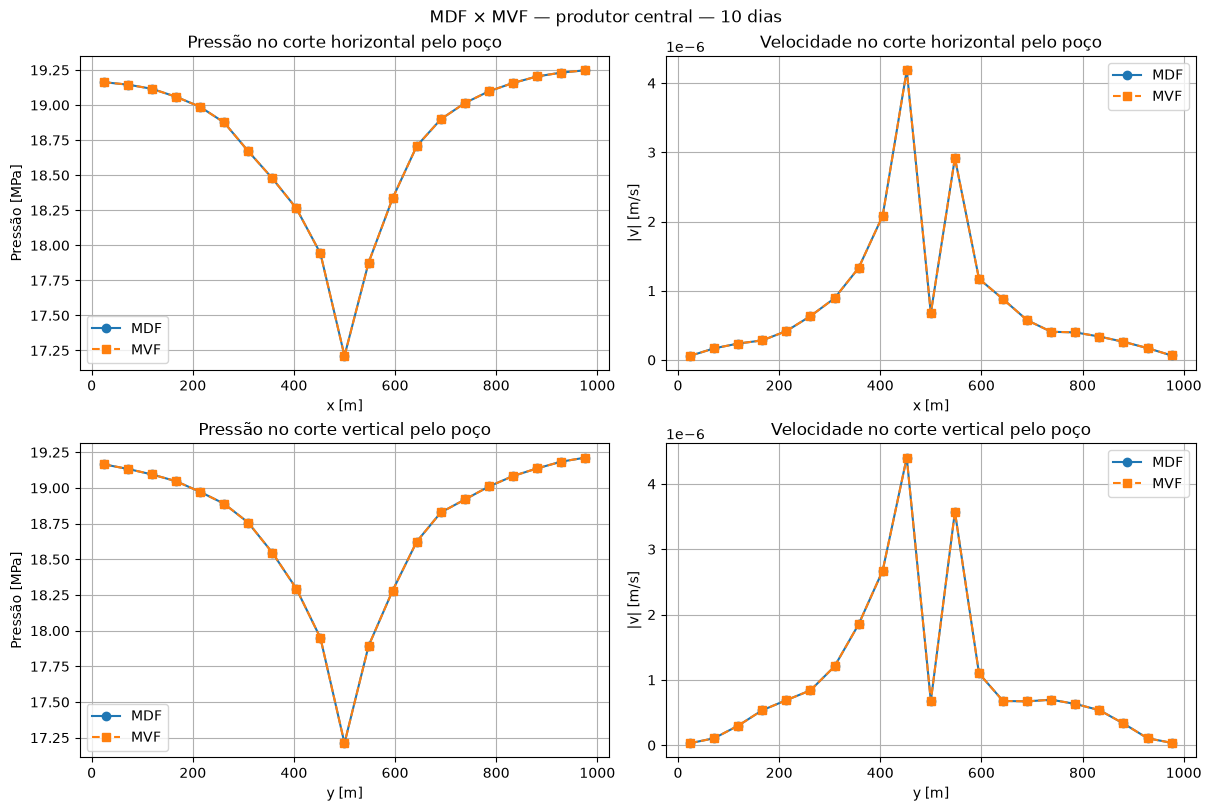

In [3]:
RESULTS_DIR = ROOT / "results" / "comparacao_mdf_mvf"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)

axes[0, 0].plot(x_mdf, P_mdf[indice_mdf, jw, :] / 1e6, "o-", label="MDF")
axes[0, 0].plot(x_mvf, P_mvf[indice_mvf, jw, :] / 1e6, "s--", label="MVF")
axes[0, 0].set(title="Pressão no corte horizontal pelo poço", xlabel="x [m]", ylabel="Pressão [MPa]")
axes[0, 0].grid()
axes[0, 0].legend()

axes[0, 1].plot(x_mdf, V_mdf[indice_mdf, jw, :], "o-", label="MDF")
axes[0, 1].plot(x_mvf, V_mvf[indice_mvf, jw, :], "s--", label="MVF")
axes[0, 1].set(title="Velocidade no corte horizontal pelo poço", xlabel="x [m]", ylabel="|v| [m/s]")
axes[0, 1].grid()
axes[0, 1].legend()

axes[1, 0].plot(y_mdf, P_mdf[indice_mdf, :, iw] / 1e6, "o-", label="MDF")
axes[1, 0].plot(y_mvf, P_mvf[indice_mvf, :, iw] / 1e6, "s--", label="MVF")
axes[1, 0].set(title="Pressão no corte vertical pelo poço", xlabel="y [m]", ylabel="Pressão [MPa]")
axes[1, 0].grid()
axes[1, 0].legend()

axes[1, 1].plot(y_mdf, V_mdf[indice_mdf, :, iw], "o-", label="MDF")
axes[1, 1].plot(y_mvf, V_mvf[indice_mvf, :, iw], "s--", label="MVF")
axes[1, 1].set(title="Velocidade no corte vertical pelo poço", xlabel="y [m]", ylabel="|v| [m/s]")
axes[1, 1].grid()
axes[1, 1].legend()

fig.suptitle(f"MDF × MVF — produtor central — {t_mdf[indice_mdf] / 86400:g} dias")
fig.savefig(RESULTS_DIR / "perfis_pressao_velocidade.pdf", bbox_inches="tight")
plt.show()


## Erro entre os métodos conforme o tamanho da malha

A permeabilidade heterogênea é reamostrada do mesmo CSV para cada malha quadrada. Em cada tamanho, MDF e MVF recebem exatamente o mesmo campo e os mesmos parâmetros. O erro relativo máximo é calculado sobre todos os tempos e células. A duração foi aumentada para 30 dias.


Base; nx=ny=9; erro relativo pressão=9.005e-15; erro relativo velocidade=2.063e-14
Maior drawdown e mobilidade; nx=ny=9; erro relativo pressão=3.242e-15; erro relativo velocidade=6.753e-15


Base; nx=ny=13; erro relativo pressão=1.801e-14; erro relativo velocidade=4.866e-14
Maior drawdown e mobilidade; nx=ny=13; erro relativo pressão=3.332e-15; erro relativo velocidade=1.441e-14


Base; nx=ny=17; erro relativo pressão=9.005e-15; erro relativo velocidade=2.846e-14


Maior drawdown e mobilidade; nx=ny=17; erro relativo pressão=1.243e-14; erro relativo velocidade=2.797e-14


Base; nx=ny=21; erro relativo pressão=1.801e-14; erro relativo velocidade=6.484e-14


Maior drawdown e mobilidade; nx=ny=21; erro relativo pressão=1.477e-14; erro relativo velocidade=3.541e-14


Base; nx=ny=25; erro relativo pressão=1.045e-14; erro relativo velocidade=5.120e-14


Maior drawdown e mobilidade; nx=ny=25; erro relativo pressão=1.495e-14; erro relativo velocidade=2.822e-14


Base; nx=ny=29; erro relativo pressão=2.666e-14; erro relativo velocidade=5.653e-14


Maior drawdown e mobilidade; nx=ny=29; erro relativo pressão=3.080e-14; erro relativo velocidade=5.026e-14


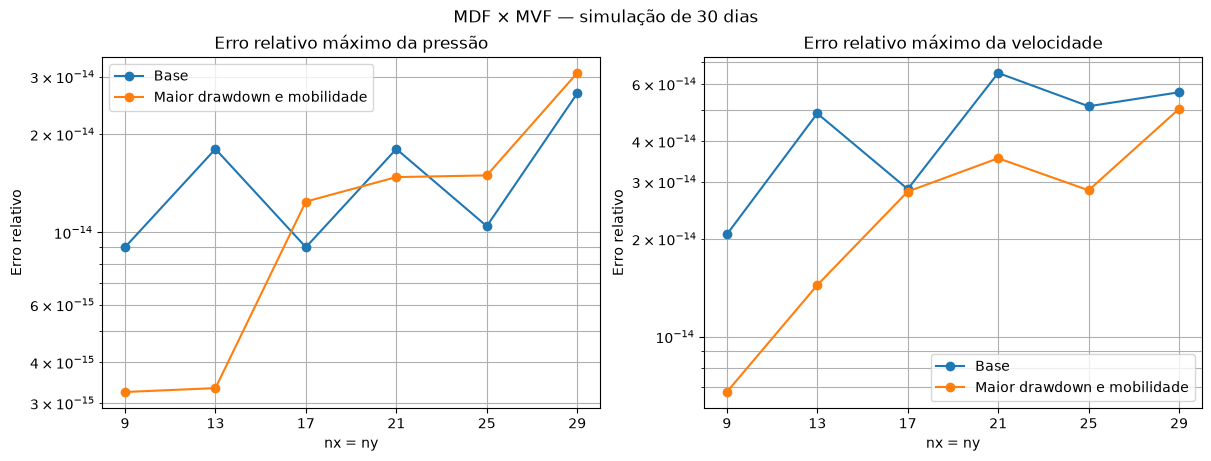

In [4]:

nx_values = [9, 13, 17, 21, 25, 29]
nt_estudo = 120
t_final_estudo = 30 * 86400
cenarios = {
    "Base": {"p0": 20.684e6, "pwf": 15.0e6, "mu": 1.0e-3, "escala_k": 1.0, "phi": 0.22, "ct": 3.046e-9},
    "Maior drawdown e mobilidade": {"p0": 20.684e6, "pwf": 10.0e6, "mu": 0.5e-3, "escala_k": 2.0, "phi": 0.22, "ct": 3.046e-9},
}
k_base_mD = carregar_permeabilidade(permeabilidade_file)
nx_base = k_base_mD.shape[1]
ny_base = k_base_mD.shape[0]
x_base = (np.arange(nx_base) + 0.5) / nx_base
y_base = (np.arange(ny_base) + 0.5) / ny_base
resultados_erro = {nome: {"pressao": [], "velocidade": []} for nome in cenarios}

for nx_estudo in nx_values:
    ny_estudo = nx_estudo
    x_alvo = (np.arange(nx_estudo) + 0.5) / nx_estudo
    y_alvo = (np.arange(ny_estudo) + 0.5) / ny_estudo
    k_intermediaria = np.array([np.interp(x_alvo, x_base, linha) for linha in k_base_mD])
    k_mD_estudo = np.array([np.interp(y_alvo, y_base, k_intermediaria[:, i]) for i in range(nx_estudo)]).T

    for nome, parametros in cenarios.items():
        k_estudo = k_mD_estudo * parametros["escala_k"] * 9.869233e-16
        iw_estudo = nx_estudo // 2
        jw_estudo = ny_estudo // 2
        argumentos = (
            parametros["p0"], parametros["pwf"], rw, h, Lx, Ly, k_estudo,
            parametros["phi"], parametros["ct"], parametros["mu"],
            t_final_estudo, nx_estudo, ny_estudo, nt_estudo,
        )
        _, _, _, P_mdf_estudo, _ = implicita_mdf(*argumentos, iw=iw_estudo, jw=jw_estudo)
        _, _, _, P_mvf_estudo, _ = implicita_mvf(*argumentos, iw=iw_estudo, jw=jw_estudo)
        _, _, V_mdf_estudo = calcular_velocidade(P_mdf_estudo, k_estudo, parametros["mu"], Lx / nx_estudo, Ly / ny_estudo, h=h)
        _, _, V_mvf_estudo = calcular_velocidade(P_mvf_estudo, k_estudo, parametros["mu"], Lx / nx_estudo, Ly / ny_estudo, h=h)

        erro_pressao = np.max(np.abs(P_mdf_estudo - P_mvf_estudo)) / np.max(np.abs(P_mvf_estudo))
        erro_velocidade = np.max(np.abs(V_mdf_estudo - V_mvf_estudo)) / np.max(np.abs(V_mvf_estudo))
        resultados_erro[nome]["pressao"].append(erro_pressao)
        resultados_erro[nome]["velocidade"].append(erro_velocidade)
        print(f"{nome}; nx=ny={nx_estudo}; erro relativo pressão={erro_pressao:.3e}; erro relativo velocidade={erro_velocidade:.3e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for nome, resultado in resultados_erro.items():
    axes[0].plot(nx_values, resultado["pressao"], "o-", label=nome)
    axes[1].plot(nx_values, resultado["velocidade"], "o-", label=nome)

axes[0].set(title="Erro relativo máximo da pressão", xlabel="nx = ny", ylabel="Erro relativo", yscale="log")
axes[1].set(title="Erro relativo máximo da velocidade", xlabel="nx = ny", ylabel="Erro relativo", yscale="log")
for ax in axes:
    ax.set_xticks(nx_values)
    ax.grid(True, which="both")
    ax.legend()

fig.suptitle("MDF × MVF — simulação de 30 dias")
fig.savefig(RESULTS_DIR / "erro_mdf_mvf_por_nx.pdf", bbox_inches="tight")
plt.show()
